In [1]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import datasets, layers, models
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import seaborn as sns

In [2]:
data = np.load("cifar-10-python.npz")

X_train = data["x_train"]
y_train = data["y_train"]
X_test = data["x_test"]
y_test = data["y_test"]

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)


In [3]:
# Normalize using min–max range
m, n = np.max(X_train), np.min(X_train)
normalised_value = m - n

print(f"Max pixel value: {m}")
print(f"Min pixel value: {n}")

X_train, X_test = X_train / normalised_value, X_test / normalised_value

print("Pixel range:", X_train.min(), "to", X_train.max())

Max pixel value: 255.0
Min pixel value: 0.0
Pixel range: 0.0 to 1.0


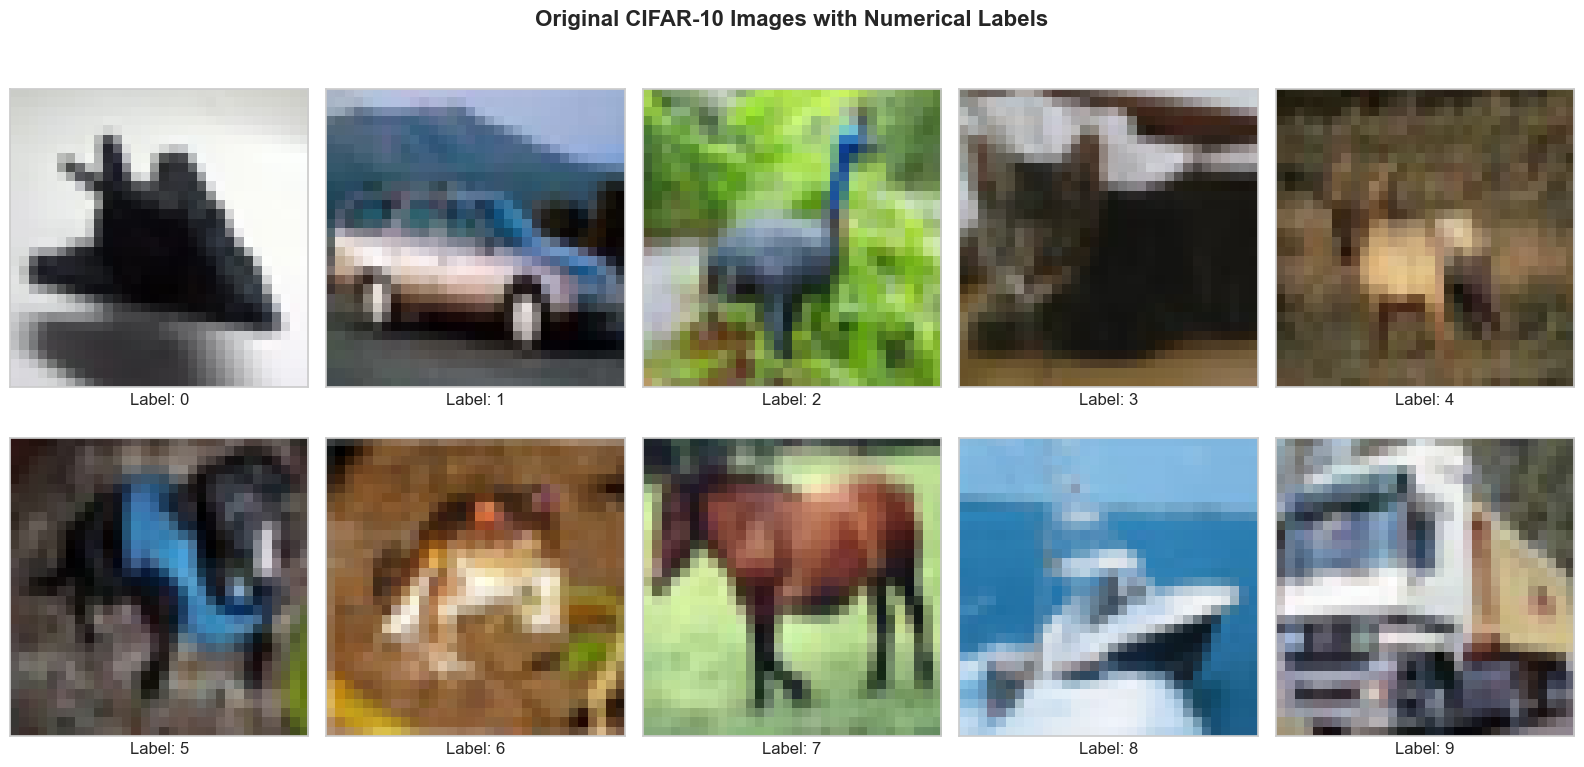

In [21]:
unique_labels, unique_indices = np.unique(y_train.flatten(), return_index=True)

plt.figure(figsize=(16, 8))
plt.suptitle("Original CIFAR-10 Images with Numerical Labels", fontsize=16, fontweight="bold")

for i, label in enumerate(unique_labels):
    index = unique_indices[i]

    # Display the original image without resizing
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[index])
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Label: {int(label)}", fontsize=12)
    plt.grid(False)

plt.tight_layout()
plt.show()

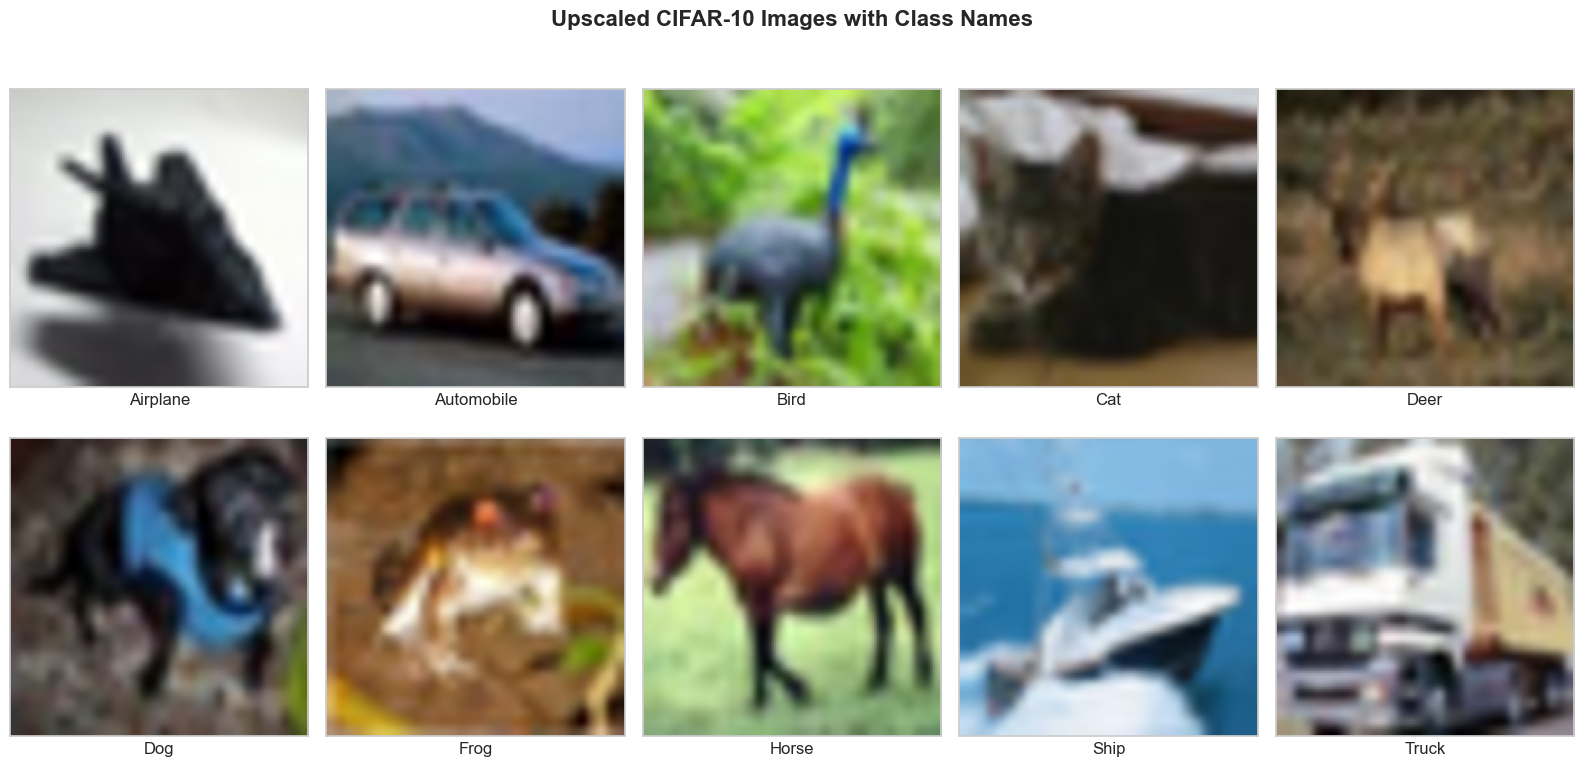

In [23]:
# Display the same sample images with class names after upscaling

class_names = ["Airplane", "Automobile", "Bird", "Cat", "Deer",
               "Dog", "Frog", "Horse", "Ship", "Truck"]

IMAGE_SIZE = 128

plt.figure(figsize=(16, 8))
plt.suptitle("Upscaled CIFAR-10 Images with Class Names", fontsize=16, fontweight="bold")

for i, label in enumerate(unique_labels):
    index = unique_indices[i]

    # Upscale this sample image for clearer display
    upscaled_image = tf.image.resize(
        X_train[index], (IMAGE_SIZE, IMAGE_SIZE), method="bicubic"
    ).numpy()
    upscaled_image = np.clip(upscaled_image, 0, 1)

    plt.subplot(2, 5, i + 1)
    plt.imshow(upscaled_image)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(class_names[int(label)], fontsize=12)
    plt.grid(False)

plt.tight_layout()
plt.show()

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(
    height_factor=0.1,
    width_factor=0.1
    ),
    layers.RandomZoom(0.1)
])

In [ ]:
model1 = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model1.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         147,520 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model2 = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 30, 30, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 15, 15, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 13, 13, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 361,898 (1.38 MB)

 Trainable params: 361,898 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model1.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

model2.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [9]:
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

In [10]:
history1 = model1.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.4409 - loss: 1.5553 - val_accuracy: 0.5626 - val_loss: 1.2589
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.5808 - loss: 1.1929 - val_accuracy: 0.6176 - val_loss: 1.1008
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.6350 - loss: 1.0523 - val_accuracy: 0.6380 - val_loss: 1.0338
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.6655 - loss: 0.9628 - val_accuracy: 0.6618 - val_loss: 0.9794
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.6858 - loss: 0.9032 - val_accuracy: 0.6780 - val_loss: 0.9355
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.7068 - loss: 0.8443 - val_accuracy: 0.7002 - val_loss: 0.8890
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.7230 - loss: 0.7984 - val_accuracy: 0.6978 - val_loss: 0.8954
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.7383 - loss: 0.7598 - 

In [11]:
history2 = model2.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 44ms/step - accuracy: 0.2622 - loss: 1.9889 - val_accuracy: 0.3806 - val_loss: 1.6982
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.4201 - loss: 1.5781 - val_accuracy: 0.4750 - val_loss: 1.4354
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.5011 - loss: 1.3840 - val_accuracy: 0.5804 - val_loss: 1.1998
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5494 - loss: 1.2656 - val_accuracy: 0.5988 - val_loss: 1.1380
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.5834 - loss: 1.1711 - val_accuracy: 0.6330 - val_loss: 1.0340
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 43ms/step - accuracy: 0.6123 - loss: 1.1013 - val_accuracy: 0.6676 - val_loss: 0.9533
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 32s 46ms/step - accuracy: 0.6316 - loss: 1.0394 - val_accuracy: 0.6734 - val_loss: 0.9376
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.6522 - loss: 0.9924 - 

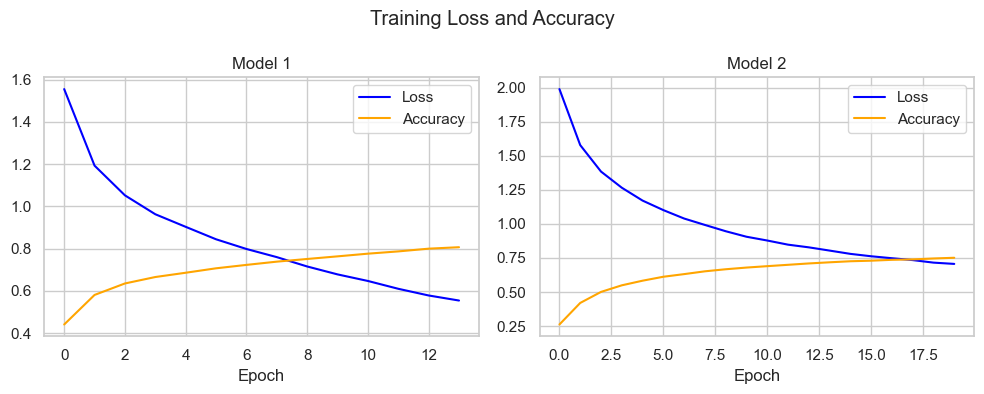

In [12]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Model 1
axes[0].plot(history1.history["loss"], color="blue", label="Loss")
axes[0].plot(history1.history["accuracy"], color="orange", label="Accuracy")
axes[0].set_title("Model 1")
axes[0].set_xlabel("Epoch")
axes[0].legend()

# Model 2
axes[1].plot(history2.history["loss"], color="blue", label="Loss")
axes[1].plot(history2.history["accuracy"], color="orange", label="Accuracy")
axes[1].set_title("Model 2")
axes[1].set_xlabel("Epoch")
axes[1].legend()

fig.suptitle("Training Loss and Accuracy")
plt.tight_layout()
plt.show()

In [13]:
test_loss1, test_acc1 = model1.evaluate(X_test, y_test, verbose=0)
test_loss2, test_acc2 = model2.evaluate(X_test, y_test, verbose=0)

print("Model 1")
print(f"Test Loss: {test_loss1:.4f}")
print(f"Test Accuracy: {test_acc1 * 100:.2f}%")

print("\nModel 2")
print(f"Test Loss: {test_loss2:.4f}")
print(f"Test Accuracy: {test_acc2 * 100:.2f}%")

Model 1
Test Loss: 0.9107
Test Accuracy: 69.38%

Model 2
Test Loss: 0.7021
Test Accuracy: 76.08%


In [14]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Model 1", "Model 2"],
    "Test Loss": [test_loss1, test_loss2],
    "Test Accuracy (%)": [test_acc1 * 100, test_acc2 * 100]
})

print(results.round(2).to_string(index=False))

  Model  Test Loss  Test Accuracy (%)
Model 1       0.91              69.38
Model 2       0.70              76.08


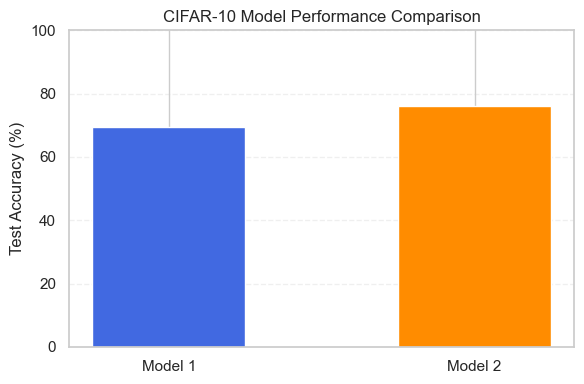

In [15]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Model 1", "Model 2"],
    [test_acc1 * 100, test_acc2 * 100],
    color=["royalblue", "darkorange"],
    width=0.5
)

plt.ylabel("Test Accuracy (%)")
plt.title("CIFAR-10 Model Performance Comparison")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
if test_acc1 > test_acc2:
    print("Model 1 performs better.")
elif test_acc2 > test_acc1:
    print("Model 2 performs better.")
else:
    print("Both models have the same test accuracy.")

Model 2 performs better.


Enter an index between 0 and 9999:  67


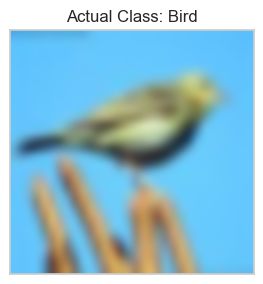


Model 1: Model 1 (Adam)
-----------------------------------
Predicted Class : Airplane
Confidence      : 68.89%
Result          : Incorrect Prediction!

Model 2: Model 2 (SGD)
-----------------------------------
Predicted Class : Bird
Confidence      : 85.84%
Result          : Correct Prediction!


In [20]:
index = int(input("Enter an index between 0 and 9999: "))

if 0 <= index < len(X_test):

    image = X_test[index]
    actual_label = int(y_test.flatten()[index])

    # Predict using both models
    pred1 = model1.predict(image.reshape(1, 32, 32, 3), verbose=0)[0]
    pred2 = model2.predict(image.reshape(1, 32, 32, 3), verbose=0)[0]

    predicted1 = np.argmax(pred1)
    predicted2 = np.argmax(pred2)

    confidence1 = np.max(pred1) * 100
    confidence2 = np.max(pred2) * 100

    # Display image in a larger figure
    plt.figure(figsize=(3, 3))
    plt.imshow(image, interpolation="bicubic")
    plt.title(
        f"Actual Class: {class_names[actual_label]}"
    )
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.tight_layout()
    plt.show()

    print("\nModel 1: Model 1 (Adam)")
    print("-" * 35)
    print(f"Predicted Class : {class_names[predicted1]}")
    print(f"Confidence      : {confidence1:.2f}%")
    print("Result          :",
          "Correct Prediction!" if predicted1 == actual_label
          else "Incorrect Prediction!")

    print("\nModel 2: Model 2 (SGD)")
    print("-" * 35)
    print(f"Predicted Class : {class_names[predicted2]}")
    print(f"Confidence      : {confidence2:.2f}%")
    print("Result          :",
          "Correct Prediction!" if predicted2 == actual_label
          else "Incorrect Prediction!")

else:
    print("Invalid index! Enter a number from 0 to 9999.")